# Cookie Cats — симуляция ложных срабатываний

Проверим, как правило остановки A/B-теста влияет на частоту ложных срабатываний. Используем двусторонний z-тест для двух долей, как в [анализе удержания](02_hypothesis_testing.ipynb), на синтетических данных с заранее известным эффектом.

## Сценарий

Симулируем **10 000 экспериментов** с одинаковой истинной вероятностью возврата на D7 в обеих группах (**20%**). В каждой группе набираем **3 000 игроков** порциями по **300**. Истинный эффект равен нулю, поэтому любое отклонение нулевой гипотезы считается ложным срабатыванием.

Сравниваем две стратегии на одних и тех же экспериментах. При **фиксированном горизонте** принимаем решение после набора 3 000 игроков на группу. При **подглядывании (peeking)** проверяем накопленные данные после каждой порции и считаем эксперимент значимым, если хотя бы раз получаем p-value < 0,05. Для воспроизводимости используем seed 2026.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

from ab_testing.simulation import simulate_false_positive_rates

In [2]:
fixed_horizon_rate, peeking_results = simulate_false_positive_rates()

## Результаты по проверкам

- `players_per_group` — число игроков в каждой группе к моменту проверки.
- `significant_at_look` — доля экспериментов со значимым результатом на этой проверке.
- `significant_by_look` — доля экспериментов, которые дали значимый результат хотя бы раз к этой проверке.

In [3]:
peeking_results

,players_per_group,significant_at_look,significant_by_look
0,300,0.0469,0.0469
1,600,0.0496,0.0819
2,900,0.0486,0.1074
3,1200,0.0511,0.1283
4,1500,0.0489,0.1429
5,1800,0.0506,0.1563
6,2100,0.0489,0.1682
7,2400,0.0484,0.1782
8,2700,0.0482,0.1867
9,3000,0.0486,0.1941


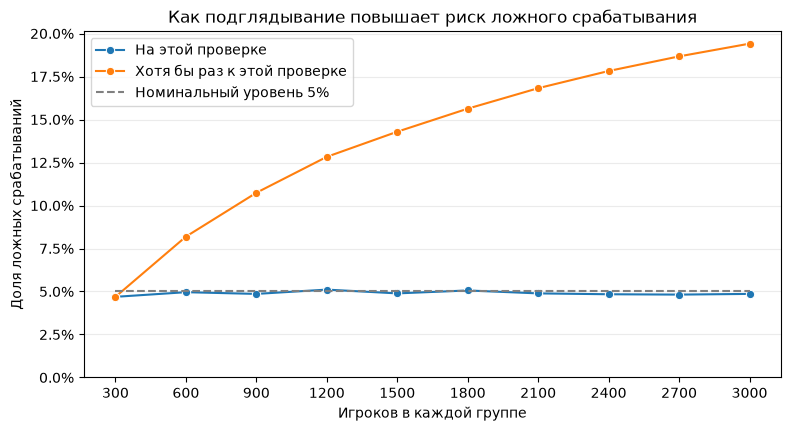

In [4]:
import matplotlib.ticker as mtick

fig, ax = plt.subplots(figsize=(9, 4.5))

sns.lineplot(
    data=peeking_results, 
    x='players_per_group',
    y='significant_at_look',
    marker='o',
    label='На этой проверке',
    ax=ax
)

sns.lineplot(
    data=peeking_results,
    x='players_per_group',
    y='significant_by_look',
    marker='o',
    label='Хотя бы раз к этой проверке',
    ax=ax
)

ax.hlines(
    y=0.05, 
    xmin=min(peeking_results['players_per_group']), 
    xmax=max(peeking_results['players_per_group']), 
    colors='grey', linestyles='--',
    label='Номинальный уровень 5%'
)

plt.title('Как подглядывание повышает риск ложного срабатывания')
plt.xticks(peeking_results['players_per_group'])
plt.ylim(bottom=0.00)
plt.xlabel('Игроков в каждой группе')
plt.ylabel('Доля ложных срабатываний')
plt.grid(visible=True, axis='y', alpha=0.25)
plt.legend()

xticks = mtick.PercentFormatter(xmax=1)
ax.yaxis.set_major_formatter(xticks)

## Вывод

На одних и тех же 10 000 экспериментах **одна финальная проверка дала 4,86% ложных срабатываний** (486 экспериментов), а **остановка при первом значимом результате из десяти проверок — 19,41%** (1 941 экспериментов). Разница составила **14,55 п.п.** Каждый новый просмотр даёт случайному колебанию ещё одну возможность пересечь порог. Эксперимент, который уже сработал, остаётся в накопленном счётчике, даже если при следующей проверке p-value выросло.

Для дизайна с фиксированным горизонтом момент проверки задаём заранее. Если команде нужна возможность остановиться раньше, правило досрочной остановки и способ контроля общей вероятности ошибки I рода нужно выбрать до начала теста. Число 19,41% относится к этому расписанию проверок на синтетических данных. Расписание проверок исходного эксперимента Cookie Cats неизвестно.